# Adversarial objectives and stabilization

Compare five fully evaluated objective/stabilization recipes on the same known
mixture. Three fitting seeds expose variation; different critic ratios and
optimizers mean matched generator updates do not imply equal compute. Historical
diffusion/flow results are context, with distinct source and sampling protocols.

**Prerequisites:** Generative objectives, independent evaluation and basic PyTorch autograd

**By the end:** Compare five objective recipes, reproduce portable predictions and verify an independent gradient-penalty oracle

Run from top to bottom. Default experiments use CPU, fixed seeds and no downloads. Small trained models illustrate learning; analytic oracles isolate mathematical and solver effects. Neither is an image-quality benchmark.

[Course index](README.md) · [Notation](../docs/23_notation_and_code.md) · [Implementation scope](../docs/15_coverage_and_scope.md)

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "diffusion_lab").is_dir())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
torch.set_num_threads(2)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    }
)
ENABLE_WIDGETS = False  # Set True in Jupyter; static figures work on GitHub.
print(f"PyTorch {torch.__version__}; CPU lesson; seed=7; no automatic downloads.")


def scatter(ax, samples, title, labels=None, limits=(-4.5, 4.5)):
    points = samples.detach().cpu().numpy()
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    ax.scatter(
        points[:, 0],
        points[:, 1],
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=5,
        alpha=0.55,
        linewidths=0,
    )
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=limits, ylim=limits)


def saved_gallery(relative, caption):
    path = project / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing curated course evidence: {relative}")
    print(caption)
    display(Image(filename=str(path)))


def animate_particles(history, name, title, labels=None, limits=(-4.5, 4.5)):
    from matplotlib.animation import FuncAnimation, PillowWriter

    points = history.detach().cpu().numpy()
    indices = np.linspace(0, len(points) - 1, min(32, len(points))).astype(int)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    dots = ax.scatter(
        *points[0].T,
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=9,
        alpha=0.65,
        linewidths=0,
    )
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="$x_1$", ylabel="$x_2$")

    def update(frame):
        dots.set_offsets(points[indices[frame]])
        ax.set_title(f"{title}: frame {frame + 1}/{len(indices)}")
        return (dots,)

    animation = FuncAnimation(fig, update, frames=len(indices), interval=100)
    folder = project / "assets/teaching/notebooks"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{name}.gif"
    animation.save(target, writer=PillowWriter(fps=10), dpi=75)
    plt.close(fig)
    display(Image(filename=str(target)))

PyTorch 2.7.1+cu128; CPU lesson; seed=7; no automatic downloads.


In [2]:
import pandas as pd

from diffusion_lab.adversarial import gradient_penalty, load_generator

rows = []
for p in (project / "assets/adversarial").glob("*/metrics.json"):
    m = json.loads(p.read_text())
    rows.append(
        {
            "method": m["config"]["method"],
            "seed": m["config"]["seed"],
            "selected": m["selected_step"],
            "MMD2": m["mmd_squared_unbiased"],
            "SW2": m["sliced_w2"],
            "inlier_fraction": m["fraction_within_3sigma"],
        }
    )
table = pd.DataFrame(rows)
assert len(table) == 15
display(table.groupby("method")[["MMD2", "SW2", "inlier_fraction"]].agg(["mean", "std"]))
%matplotlib inline

MMD2                 SW2           inlier_fraction  \
                       mean       std      mean       std            mean   
method                                                                      
hinge_spectral     0.002737  0.000555  0.136907  0.005596        0.804362   
least_squares      0.004588  0.001071  0.238304  0.022702        0.844401   
non_saturating_r1  0.002597  0.000170  0.134827  0.016951        0.838053   
wasserstein_clip   0.016748  0.000230  0.228905  0.004430        0.558431   
wasserstein_gp     0.006378  0.000720  0.171812  0.001518        0.748128   

                             
                        std  
method                       
hinge_spectral     0.015035  
least_squares      0.011538  
non_saturating_r1  0.014236  
wasserstein_clip   0.021771  
wasserstein_gp     0.027136

## Portable generator and independent test draws

No private checkpoint, dataset download or GPU is needed. The published small
NPZ file is checked against its metadata digest. This is direct generation, not
a diffusion denoising trajectory.

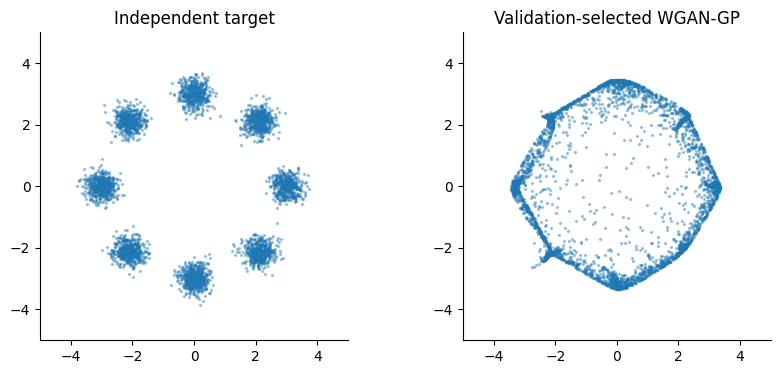

In [3]:
folder = project / "assets/adversarial/wasserstein_gp_42"
model = load_generator(folder)
source = np.load(folder / "samples.npz", allow_pickle=False)
with torch.no_grad():
    fresh = model(torch.from_numpy(source["latent"]))
np.testing.assert_array_equal(fresh.numpy(), source["generated"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, values, title in zip(
    axes,
    [source["reference"], fresh.numpy()],
    ["Independent target", "Validation-selected WGAN-GP"],
    strict=True,
):
    ax.scatter(*values.T, s=2, alpha=0.35)
    ax.set(title=title, aspect="equal", xlim=(-5, 5), ylim=(-5, 5))
plt.show()

Linear input-gradient norm 5 gives (5−1)² = 16.0


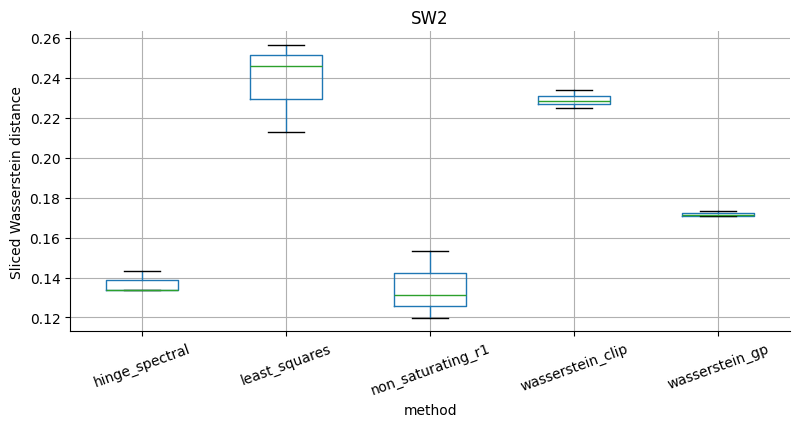

In [4]:
critic = torch.nn.Linear(2, 1, bias=False)
with torch.no_grad():
    critic.weight.copy_(torch.tensor([[3.0, 4.0]]))
penalty = gradient_penalty(
    critic, torch.randn(16, 2), torch.randn(16, 2), torch.Generator().manual_seed(7)
)
assert abs(float(penalty) - 16) < 1e-5
print("Linear input-gradient norm 5 gives (5−1)² =", float(penalty))
fig, ax = plt.subplots(figsize=(9, 4))
table.boxplot(column="SW2", by="method", ax=ax, rot=20)
fig.suptitle("")
ax.set_ylabel("Sliced Wasserstein distance")
plt.show()

## What does the comparison establish?

Report coverage together with inliers and mode mass. A generator that hits each
mode once can still put most outputs between modes. Target cross-entropy is not
generator likelihood. A critic's raw objective also cannot compare GAN recipes
that optimize different quantities. Read the complete [protocol](../docs/30_portfolio_review.md)
and try the [offline explorer](../docs/explorer.html) before interpreting the figures.